In [15]:
from __future__ import annotations

import copy
import csv
import json
import re
from pathlib import Path
from typing import Any

import h5py
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
import numpy as np
from scipy.ndimage import zoom
from scipy.spatial import cKDTree
from tqdm import tqdm
import importlib

In [16]:
#step 1
class BraTSSliceDataset(Dataset):
    def __init__(self, files: list[Path]) -> None:
        self.files = list(files)

    def __len__(self) -> int:
        return len(self.files)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor, str]:
        path = self.files[index]
        with h5py.File(path, "r") as h5_file:
            image = np.asarray(h5_file["image"][...], dtype=np.float32)
            mask = np.asarray(h5_file["mask"][...], dtype=np.float32)

        # Validate tensor dimensions
        if image.ndim != 3 or image.shape[-1] != 4:
            raise ValueError(f"{path.name}: expected image shape (H, W, 4), got {image.shape}")
        if mask.shape != (*image.shape[:2], N_MASK_CHANNELS):
            raise ValueError(f"{path.name}: unexpected mask shape {mask.shape}")

        # Per-slice intensity normalization to [-1, 1]
        scale = np.max(np.abs(image), axis=(0, 1), keepdims=True)
        scale[scale < 1e-6] = 1.0
        image = np.clip(image / scale, -1.0, 1.0)
        
        # Convert to PyTorch tensors and permute to (C, H, W)
        image_tensor = torch.from_numpy(image).permute(2, 0, 1)
        mask_tensor = torch.from_numpy((mask > 0).astype(np.float32)).permute(2, 0, 1)
        return image_tensor, mask_tensor, path.name

In [17]:
#step 2
def split_by_volume(
    files: list[Path], seed: int
) -> tuple[list[Path], list[Path], list[Path]]:
    volume_pattern = re.compile(r"volume_(\d+)_slice_")
    volume_files: dict[str, list[Path]] = {}
    for path in files:
        match = volume_pattern.search(path.name)
        if match is None:
            raise ValueError(f"Unexpected slice filename: {path.name}")
        volume_files.setdefault(match.group(1), []).append(path)

    volume_ids = np.asarray(sorted(volume_files))
    rng = np.random.default_rng(seed)
    rng.shuffle(volume_ids)
    
    n_volumes = len(volume_ids)
    n_train = int(n_volumes * 0.70)
    n_val = int(n_volumes * 0.15)
    
    train_ids = set(volume_ids[:n_train])
    val_ids = set(volume_ids[n_train:n_train + n_val])
    test_ids = set(volume_ids[n_train + n_val:])

    train = [p for v in train_ids for p in volume_files[v]]
    val = [p for v in val_ids for p in volume_files[v]]
    test = [p for v in test_ids for p in volume_files[v]]
    
    for group in (train, val, test):
        group.sort()
        
    if train_ids & val_ids or train_ids & test_ids or val_ids & test_ids:
        raise RuntimeError("Volume split contains leakage.")
    return train, val, test

In [18]:
#step 3
class DoubleConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int) -> None:
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.layers(x)


class UNet2D(nn.Module):
    def __init__(self, in_channels: int = 4, out_channels: int = 3, width: int = 8) -> None:
        super().__init__()
        self.pool = nn.MaxPool2d(2)
        self.enc1 = DoubleConv(in_channels, width)
        self.enc2 = DoubleConv(width, width * 2)
        self.enc3 = DoubleConv(width * 2, width * 4)
        self.enc4 = DoubleConv(width * 4, width * 8)
        self.bottleneck = DoubleConv(width * 8, width * 16)
        
        self.up4 = nn.ConvTranspose2d(width * 16, width * 8, 2, stride=2)
        self.dec4 = DoubleConv(width * 16, width * 8)
        self.up3 = nn.ConvTranspose2d(width * 8, width * 4, 2, stride=2)
        self.dec3 = DoubleConv(width * 8, width * 4)
        self.up2 = nn.ConvTranspose2d(width * 4, width * 2, 2, stride=2)
        self.dec2 = DoubleConv(width * 4, width * 2)
        self.up1 = nn.ConvTranspose2d(width * 2, width, 2, stride=2)
        self.dec1 = DoubleConv(width * 2, width)
        self.output = nn.Conv2d(width, out_channels, 1)

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        bottleneck = self.bottleneck(self.pool(e4))

        d4 = self.dec4(torch.cat([self.up4(bottleneck), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.output(d1), bottleneck

In [19]:
#step 4
def mask_positive_weights(files: list[Path], device: torch.device) -> torch.Tensor:
    positives = np.zeros(N_MASK_CHANNELS, dtype=np.float64)
    total_pixels = 0
    for path in tqdm(files, desc="Counting training mask pixels", unit="slice"):
        with h5py.File(path, "r") as h5_file:
            mask = np.asarray(h5_file["mask"][...]) > 0
        positives += mask.sum(axis=(0, 1))
        total_pixels += mask.shape[0] * mask.shape[1]

    negatives = total_pixels - positives
    weights = negatives / np.maximum(positives, 1.0)
    return torch.as_tensor(np.clip(weights, 1.0, 20.0), dtype=torch.float32, device=device)


def segmentation_loss(
    logits: torch.Tensor,
    masks: torch.Tensor,
    pos_weight: torch.Tensor,
    sample_class_weights: torch.Tensor | None = None,
) -> torch.Tensor:
    bce = F.binary_cross_entropy_with_logits(
        logits,
        masks,
        pos_weight=pos_weight.view(1, -1, 1, 1),
        reduction="none",
    ).mean(dim=(2, 3))

    probabilities = torch.sigmoid(logits)
    intersection = (probabilities * masks).sum(dim=(2, 3))
    denominator = probabilities.sum(dim=(2, 3)) + masks.sum(dim=(2, 3))
    dice_loss = 1.0 - (2.0 * intersection + 1.0) / (denominator + 1.0)
    per_sample_class_loss = bce + dice_loss

    if sample_class_weights is not None:
        per_sample_class_loss = per_sample_class_loss * sample_class_weights
    return per_sample_class_loss.mean()

In [20]:
#step 5
def class_semantic_scales(
    features: torch.Tensor, masks: torch.Tensor
) -> np.ndarray:
    resized_mask = F.adaptive_avg_pool2d(
        masks.unsqueeze(0), output_size=features.shape[-2:]
    )[0] > 0.5
    scales = np.full(N_MASK_CHANNELS, np.nan, dtype=np.float32)

    for class_index in range(N_MASK_CHANNELS):
        selected = resized_mask[class_index].flatten()
        if int(selected.sum()) < 2:
            continue
        matrix = features.float().flatten(1)[:, selected]
        matrix = matrix - matrix.mean(dim=1, keepdim=True)
        singular_values = torch.linalg.svdvals(matrix)
        energy = singular_values.square()
        energy_sum = energy.sum()
        rank = energy.numel()
        if rank <= 1 or energy_sum <= 1e-12:
            scales[class_index] = 0.0
            continue
        probabilities = energy / energy_sum
        probabilities = probabilities.clamp_min(1e-12)
        entropy = -(probabilities * probabilities.log()).sum()
        scales[class_index] = (entropy / np.log(rank)).item()

    return scales


def derive_uncertainty_weights(
    model: UNet2D,
    train_files: list[Path],
    device: torch.device,
) -> dict[str, np.ndarray]:
    model.eval()
    scales_by_name: dict[str, np.ndarray] = {}
    all_scales: list[list[float]] = [[] for _ in range(N_MASK_CHANNELS)]
    loader = make_loader(train_files, batch_size=1, shuffle=False)

    with torch.inference_mode():
        for images, masks, names in tqdm(
            loader, desc="Estimating training feature entropy", unit="slice"
        ):
            _, features = model(images.to(device))
            scales = class_semantic_scales(features[0], masks[0].to(device))
            scales_by_name[names[0]] = scales
            for class_index, value in enumerate(scales):
                if np.isfinite(value):
                    all_scales[class_index].append(float(value))

    result: dict[str, np.ndarray] = {}
    for name, scales in scales_by_name.items():
        weights = np.ones(N_MASK_CHANNELS, dtype=np.float32)
        for class_index, values in enumerate(all_scales):
            value = scales[class_index]
            if not np.isfinite(value) or not values:
                continue
            log_values = np.log(np.maximum(np.asarray(values), 1e-8))
            low, high = float(log_values.min()), float(log_values.max())
            if high - low <= 1e-8:
                auv = 0.0
            else:
                auv = 1.0 - (np.log(max(float(value), 1e-8)) - low) / (high - low)
            weights[class_index] = np.clip(1.0 - 0.75 * auv, 0.25, 1.0)
        result[name] = weights
    return result

In [21]:
#step 6
def pca_four_channels(feature_tensor: torch.Tensor) -> np.ndarray:
    feature_map = feature_tensor.detach().float().cpu().numpy()
    channels, height, width = feature_map.shape
    vectors = feature_map.reshape(channels, -1).T.astype(np.float64)
    vectors -= vectors.mean(axis=0, keepdims=True)
    u, singular_values, _ = np.linalg.svd(vectors, full_matrices=False)
    reduced_channels = min(PCA_CHANNELS, u.shape[1])
    reduced = u[:, :reduced_channels] * singular_values[:reduced_channels]
    if reduced_channels < PCA_CHANNELS:
        reduced = np.pad(reduced, ((0, 0), (0, PCA_CHANNELS - reduced_channels)))
    return reduced.reshape(height, width, PCA_CHANNELS).astype(np.float32)


def gbc_refined_probabilities(
    feature_tensor: torch.Tensor,
    probabilities: torch.Tensor,
    segmenter_class: type,
) -> torch.Tensor:
    latent_features = pca_four_channels(feature_tensor)
    cluster_map = segmenter_class().fit(
        latent_features, spatial_weight=0.1, show_progress=False
    )
    cluster_ids = np.unique(cluster_map)
    cluster_tensor = torch.as_tensor(
        cluster_map, dtype=torch.float32, device=probabilities.device
    )[None, None]
    coarse_probabilities = F.adaptive_avg_pool2d(
        probabilities.unsqueeze(0), output_size=cluster_map.shape
    )[0]
    coarse_refined = torch.zeros_like(coarse_probabilities)

    for cluster_id in cluster_ids:
        region = cluster_tensor[0, 0] == int(cluster_id)
        coarse_refined[:, region] = coarse_probabilities[:, region].mean(
            dim=1, keepdim=True
        )

    return F.interpolate(
        coarse_refined.unsqueeze(0),
        size=probabilities.shape[-2:],
        mode="bilinear",
        align_corners=False,
    )[0]

In [22]:
class GrandularBall3D:
    def __init__(self, points):
        self.points = np.array(points, dtype=np.float64)
        self.dim = self.points.shape[1]
        self.center = np.mean(self.points,axis=0)
        self.radius_max = 0.0
        self.radius_avg = 0.0
        self.radius_sta = 0.0
        self.mu = None
        self.nu = None
        self.pi = None
        self.scm = 1.0

    def compute_intuitionistic_fuzzy_parameters(self,alpha=0.7):
        n = len(self.points)
        if n == 0:
            return 
        diffs = self.points - self.center
        dist_sq = np.sum(diffs ** 2, axis=1)
        r_max_temp = np.max(dist_sq) if n > 1 else 1e-5
        sigma_m = alpha * np.sqrt(r_max_temp + 1e-8)
        sigma_m = max(sigma_m, 1e-5)
        sigma_n = (1.0 - alpha) * np.sqrt(r_max_temp + 1e-8)
        sigma_n = max(sigma_n, 1e-5)

        self.mu = np.exp(-dist_sq / (sigma_m ** 2))
        self.nu = 1.0 - np.exp(-dist_sq / (sigma_n ** 2))

        self.pi = np.clip(1.0 - self.mu - self.nu, 0.0, 1.0)
        theta_pi = self.pi[:,np.newaxis]
        self.center = np.mean(self.points + theta_pi, axis=0)

        diffs = self.points - self.center
        dist_pi = np.sum(diffs ** 2,axis=1) + self.pi

        self.radius_max = np.max(dist_pi) if n > 1 else 1e-5
        self.radius_avg = np.mean(dist_pi) if n > 1 else 1e-5
        



In [23]:
class SegGBC:
    def __init__(self, beta=0.8, epsilon=0.75, alpha=0.7):
        self.beta = beta
        self.epsilon = epsilon
        self.alpha = alpha
        self.balls = []

    def fit(self, image, spatial_weight=0.1, show_progress=True):
        if image.ndim !=3 or image.shape[-1] !=4:
            raise ValueError(f"Expected image shape (H, W, 4); got {image.shape}")
        if spatial_weight <=0:
            raise ValueError("spatial_weight must be greater than 0")

        H,W,C = image.shape

        if show_progress:
            print("constructing 2d feature space...")
        # Scale each modality without assuming the image values are 0–255.
        image = image.astype(np.float64)
        scales = np.max(np.abs(image), axis=(0, 1), keepdims=True)
        scales[scales == 0] = 1.0
        normalized_image = image / scales

        yy, xx = np.meshgrid(np.arange(H), np.arange(W), indexing="ij")

        features = np.column_stack([
            normalized_image.reshape(-1, C),
            xx.reshape(-1).astype(np.float64) / W * spatial_weight,
            yy.reshape(-1).astype(np.float64) / H * spatial_weight,
        ])

        intital_ball = GrandularBall3D(features)
        intital_ball.compute_intuitionistic_fuzzy_parameters(self.alpha)
        self.balls = [intital_ball]

        if show_progress:
            print("running scm-driven adaptive splitting iterations...")
        iteration = 0
        max_iter = 30

        with tqdm(total=max_iter, desc="Splitting Progress", unit='iter', disable=not show_progress) as pbar:
            while iteration < max_iter:
                iteration +=1
                new_balls = []
                split_occurred = False

                for ball in self.balls:
                    ball.compute_intuitionistic_fuzzy_parameters(self.alpha)
                    ball.radius_sta = ball.radius_avg * 0.5

                    d = ball.dim
                    r_max_vol = max(ball.radius_max ** d, 1e-8)
                    r_avg_vol = max(ball.radius_avg ** d, 1e-8)
                    r_sta_vol = max(ball.radius_sta ** d, 1e-8)

                    rho_max = len(ball.points) / r_max_vol

                    diffs = ball.points - ball.center
                    dist_pi = np.sum(diffs ** 2, axis=1) + ball.pi

                    rho_avg = np.sum(dist_pi <= ball.radius_avg) / r_avg_vol
                    rho_sta = np.sum(dist_pi <= ball.radius_sta) / r_sta_vol

                    num = min(rho_avg,rho_max) * min(rho_sta, rho_max)
                    den = max(rho_avg, rho_max) * max(rho_sta, rho_max) + 1e-8

                    ball.scm = num / den

                    if ball.scm < self.beta and len(ball.points) > 20:
                        split_occurred = True
                        mid = len(ball.points) // 2
                        new_balls.extend([
                            GrandularBall3D(ball.points[:mid]),
                            GrandularBall3D(ball.points[mid:])
                        ])
                    else:
                        new_balls.append(ball)

                self.balls = new_balls

                pbar.set_postfix(balls_count=len(self.balls))
                pbar.update(1)
                if not split_occurred:
                    break
        if show_progress:
            print(f"\nMerging clusters (Total active balls: {len(self.balls)}) ....")
        self._merge_clusters(show_progress=show_progress)

        if show_progress:
            print("Generating final 2D segmentation map...")
        seg_mask = self._generate_2D_mask(H, W, spatial_weight)
        return seg_mask

    def _merge_clusters(self, show_progress=True):
        if len(self.balls) <=1:
            return

        if show_progress:
            print("Building spatial KD-Tree for fast neighbour lookup...")

        centers = np.array([b.center for b in self.balls])
        tree = cKDTree(centers)

        avg_radius = np.mean([b.radius_max for b in self.balls])
        neighbour_radius = max(avg_radius * 3.0, 1.0)

        pairs = tree.query_pairs(r=neighbour_radius)

        merged_indices = set()

        with tqdm(pairs, desc="Merging Progress", unit="pairs", disable=not show_progress) as pbar:
            for i,j in pbar:
                if i in merged_indices or j in merged_indices:
                    continue

                b1, b2 = self.balls[i], self.balls[j]

                dist_centers = np.linalg.norm(b1.center - b2.center)
                sim = 1.0/(1.0 + dist_centers)

                if sim > self.epsilon:
                    merged_indices.add(j)
                    b1.points = np.vstack([b1.points, b2.points])
                    b1.compute_intuitionistic_fuzzy_parameters(self.alpha)
                    pbar.set_postfix(merged=len(merged_indices))

        initial_count = len(self.balls)
        self.balls = [b for idx,b in enumerate(self.balls) if idx not in merged_indices]
        if show_progress:
            print(f"Merging complete! Reduced from {initial_count} balls down to {len(self.balls)} clusters")

    def _generate_2D_mask(self, H, W, spatial_weight):
        mask = np.zeros((H, W), dtype=np.int32)

        for cluster_id, ball in enumerate(self.balls):
            for pt in ball.points:
                x = int(round(pt[4] * W / spatial_weight))
                y = int(round(pt[5] * H / spatial_weight))

                if 0 <= y < H and 0 <= x < W:
                    mask[y, x] = cluster_id

        return mask
    




Split by volume: train=39990 slices, validation=8525, test=8680
Training device: cuda


Counting training mask pixels:   0%|          | 0/39990 [00:00<?, ?slice/s]

Training epoch 1/5:   0%|          | 0/9998 [00:00<?, ?batch/s]

Epoch 1/5: train_loss=0.5533, val_loss=0.3648


Training epoch 2/5:   0%|          | 0/9998 [00:00<?, ?batch/s]

Epoch 2/5: train_loss=0.3490, val_loss=0.3243


... (12 outputs left out)

Tuning on validation volumes:   0%|          | 0/250 [00:00<?, ?slice/s]

Validation-selected U-Net-only thresholds: [0.75 0.75 0.55]
Validation-selected per-channel alpha (baseline): [0.25 0.25 0.  ]
Validation-selected per-channel thresholds (baseline): [0.7  0.7  0.55]
Validation Dice at selected settings (baseline): [0.5299214  0.67165947 0.59634644]
Validation-selected uncertainty-U-Net-only thresholds: [0.75 0.75 0.45]
Validation-selected per-channel alpha (uncertainty): [0.25 0.25 0.  ]
Validation-selected per-channel thresholds (uncertainty): [0.7  0.7  0.45]
Validation Dice at selected settings (uncertainty): [0.5199225 0.7019788 0.6546907]


Final held-out test:   0%|          | 0/8680 [00:00<?, ?slice/s]

Saved metrics to /home/aman_kumar/nas/research/vc_project/unet_seggbc_experiment_results.json
unet: combined Dice=0.8313, combined IoU=0.7112, per-channel Dice=[0.3556 0.6656 0.6286]
unet: macro BCE=0.016124, macro Brier=0.003879, macro ECE=0.004221
unet_gbc: combined Dice=0.8452, combined IoU=0.7319, per-channel Dice=[0.3906 0.6887 0.6286]
unet_gbc: macro BCE=0.012457, macro Brier=0.002918, macro ECE=0.003892
unet_uncertainty: combined Dice=0.8558, combined IoU=0.7480, per-channel Dice=[0.4279 0.693  0.7036]
unet_uncertainty: macro BCE=0.013164, macro Brier=0.003128, macro ECE=0.003362
unet_uncertainty_gbc: combined Dice=0.8635, combined IoU=0.7598, per-channel Dice=[0.474  0.7121 0.7036]
unet_uncertainty_gbc: macro BCE=0.010326, macro Brier=0.002364, macro ECE=0.003105


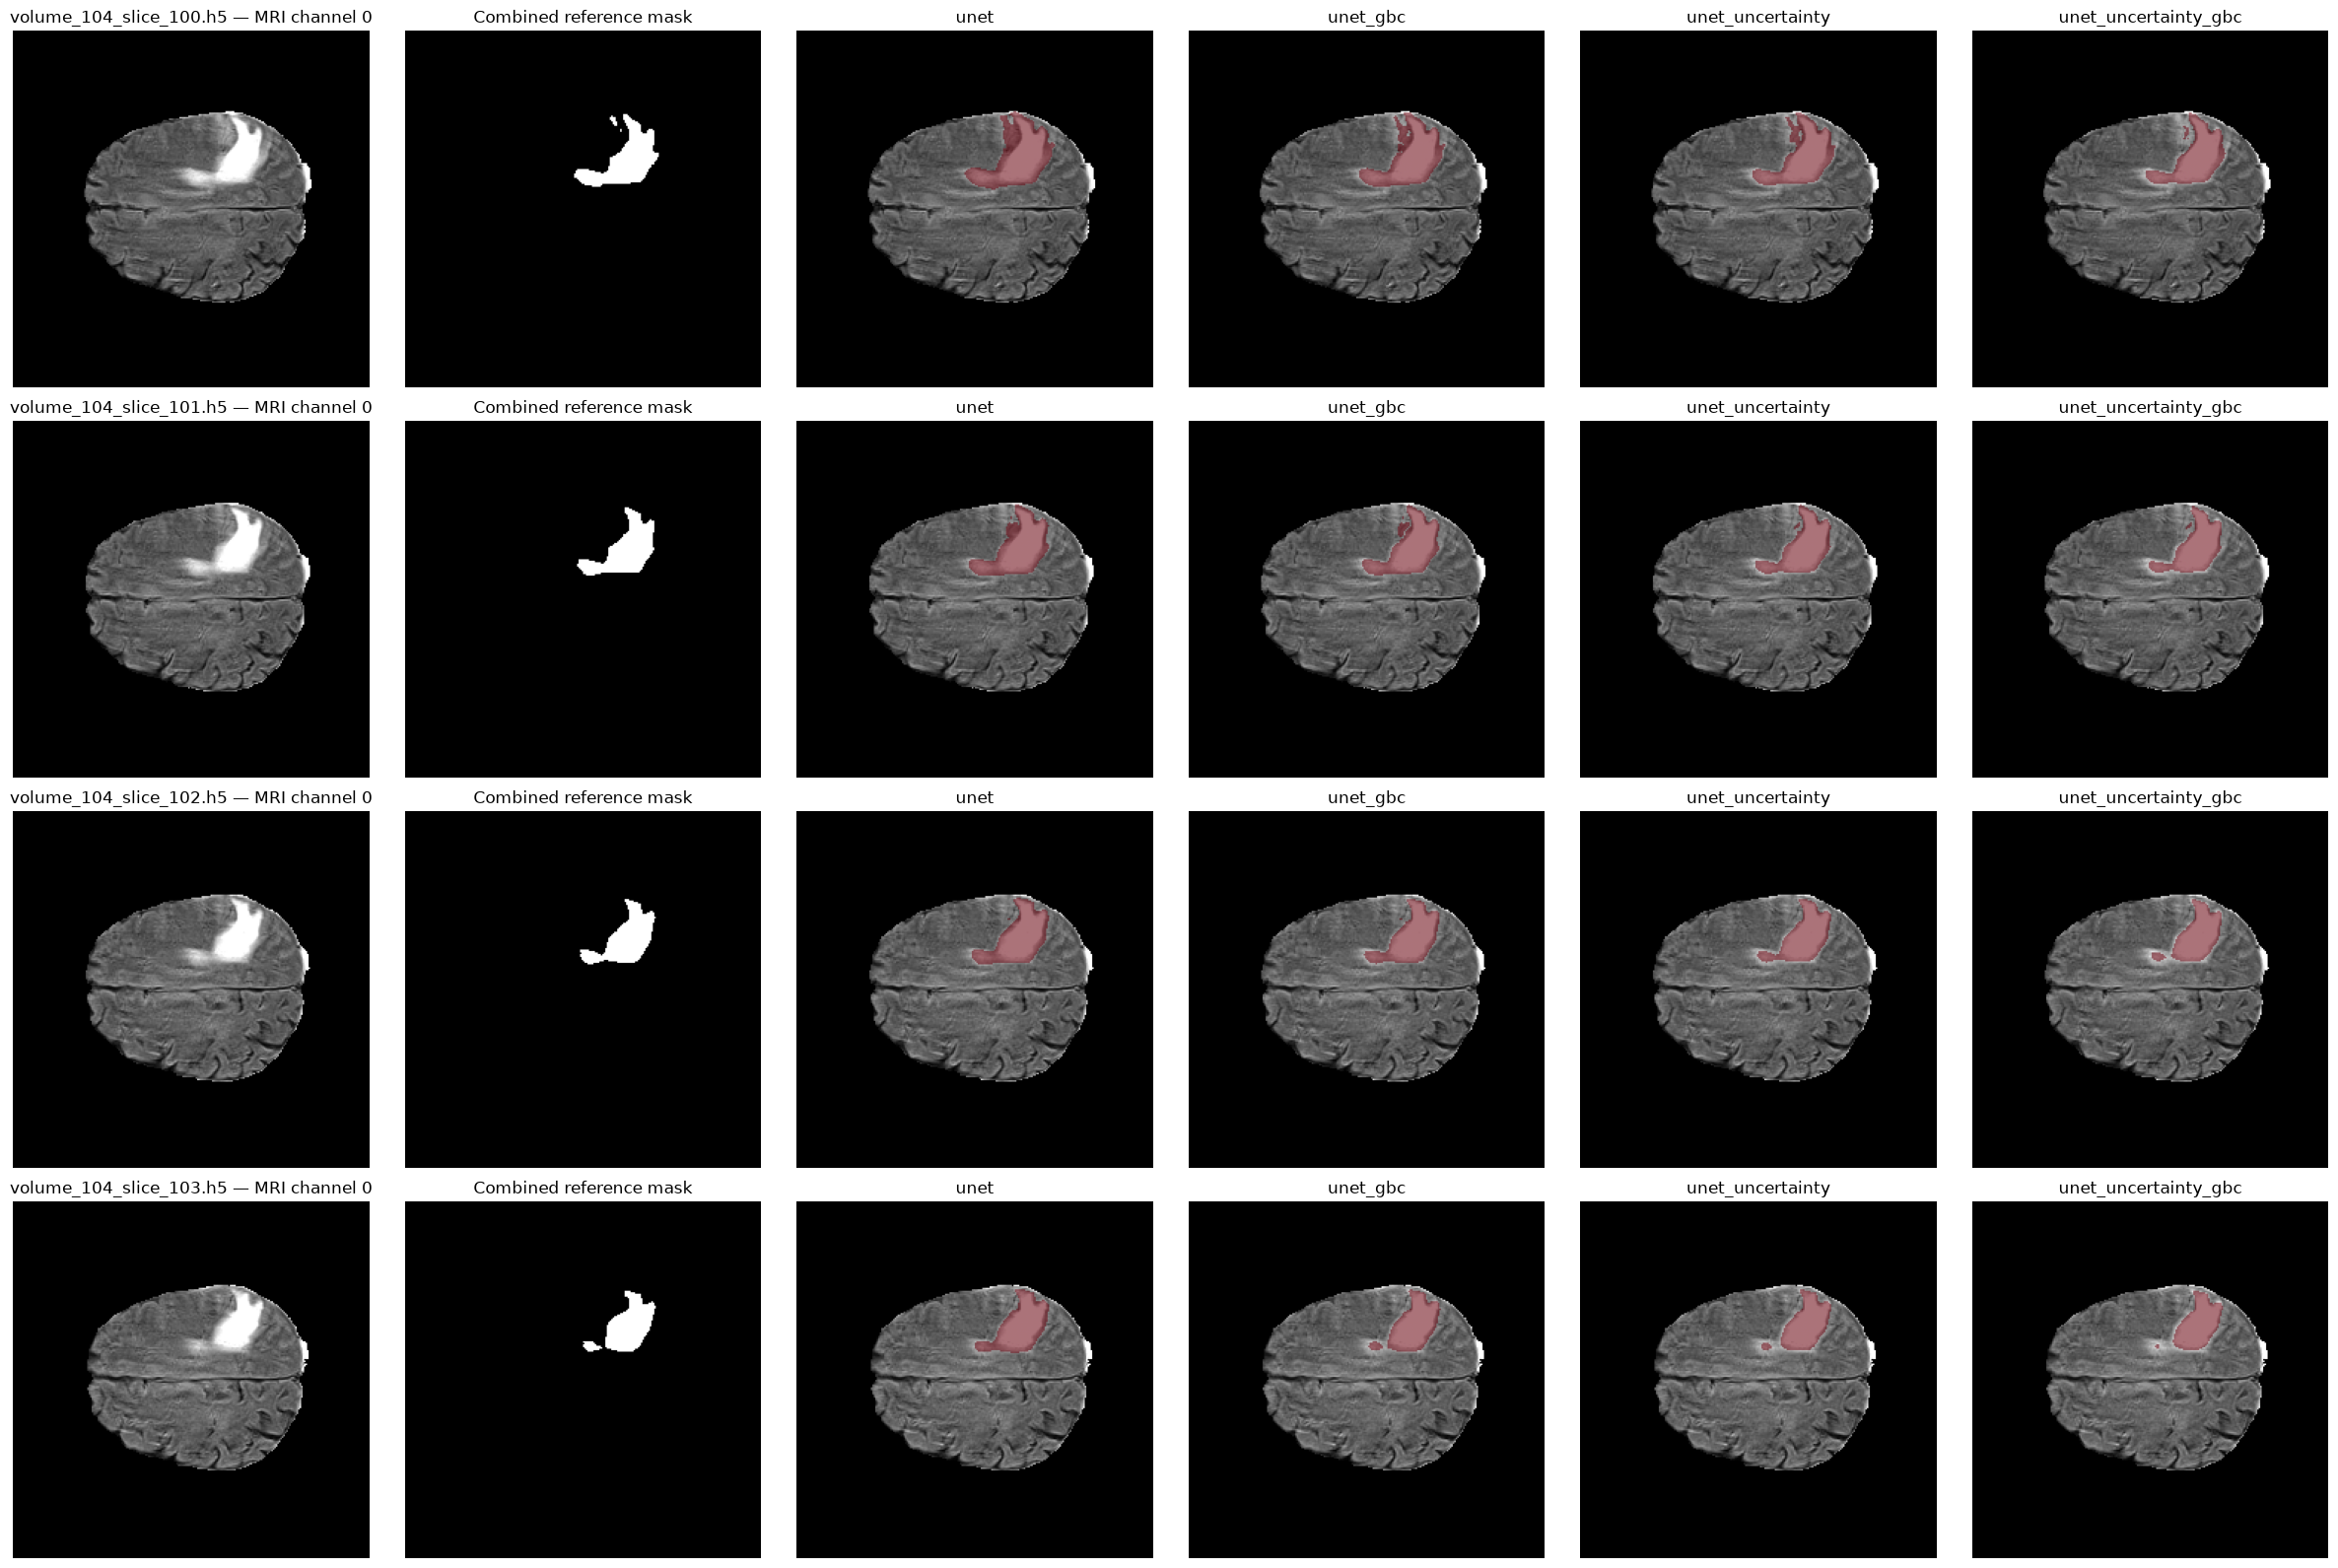

In [24]:
import importlib
import unet_seggbc_experiment as exp

exp = importlib.reload(exp)
summary = exp.run_experiment(
    data_dir="data/3/BraTS2020_training_data/content/data",
    segmenter_class=SegGBC,
)